# Week 8 Assignment
## DATA 620
### Jane Song

Assignment instructions:

1. Choose a corpus of interest.
2. How many total unique words are in the corpus? (Please feel free to define unique words in any interesting, defensible way).
3. Taking the most common words, how many unique words represent half of the total words in the corpus?
4. Identify the 200 highest frequency words in this corpus.
5. Create a graph that shows the relative frequency of these 200 words.
6. Does the observed relative frequency of these words follow Zipf’s law? Explain.
7. In what ways do you think the frequency of the words in this corpus differ from “all words in all corpora.”

## Introduction 

For this assignment, I have selected to use the Alice in Wonderland novel as my corpus. I've always loved this book and everytime I read it or watch any films based on it I notice something new. I was able to find a corpus of the entire novel in github to use for this task. 


## Load corpus

In [24]:
import urllib.request
import re
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd

url = "https://raw.githubusercontent.com/dakrone/corpus/master/data/alice-in-wonderland.txt"

with urllib.request.urlopen(url) as response:
    text = response.read().decode("utf-8-sig")

print(text[:500])
print("Total characters", len(text))



Project Gutenberg's Alice's Adventures in Wonderland, by Lewis Carroll

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or online at www.gutenberg.org


Title: Alice's Adventures in Wonderland

Author: Lewis Carroll

Posting Date: June 25, 2008 [EBook #11]
Release Date: March, 1994

Language: English


*** START
Total characters 167497


## Evaluate corpus word frequency

In [18]:
# Find the beginning and end of the story
start_mark = "*** START OF THIS PROJECT GUTENBERG EBOOK ALICE'S ADVENTURES IN WONDERLAND ***"
end_mark = "THE END"

start = text.find(start_mark)
end = text.find(end_mark)

if start != -1:
    text = text[start + len(start_mark):]

if end != -1:
    text = text[:text.find(end_mark)]

# Standardize capitalization and extract words
words = re.findall(r"\b[a-z]+\b", text.lower())
word_counts = Counter(words)

print("Total words:", len(words))
print("Total unique words:", len(word_counts))
print("Top 10 words:", word_counts.most_common(10))

Total words: 27336
Total unique words: 2572
Top 10 words: [('the', 1643), ('and', 872), ('to', 729), ('a', 632), ('it', 595), ('she', 553), ('i', 543), ('of', 514), ('said', 462), ('you', 411)]


This text has 27,336 total words and 2572 unique words. The 10 most common words are `the`, `and`, `to`, `a`, `it`, `she`, `i`, `of`, `said`, and `you`. I'm not surprised as these are common stop words that would naturally exist in a novel. To keep it more interesting, I will remove the stops words and see what the most common words are using the nltk library. 

In [19]:

import nltk
from nltk.corpus import stopwords
nltk.download("stopwords")

# Extract lowercase words
words = re.findall(r"\b[a-z]+\b", text.lower())

# Remove stop words
stop_words = set(stopwords.words("english"))

filtered_words = [word for word in words if word not in stop_words]

# Count remaining words
word_counts = Counter(filtered_words)

print("Total words after removing stop words:", len(filtered_words))
print("Unique words after removing stop words:", len(word_counts))
print("Top 10 words:", word_counts.most_common(10))


Total words after removing stop words: 12243
Unique words after removing stop words: 2426
Top 10 words: [('said', 462), ('alice', 398), ('little', 128), ('one', 104), ('know', 88), ('like', 85), ('would', 83), ('went', 83), ('could', 77), ('queen', 75)]


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\janej\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


After removing the stop words, there are 12,243 words and 2426 unique words, significantly less total words than the original corpus. The most common words are `said`, `alice`, `little`, `one`, `know`, `like`, `would`, `went`, `could`, and `queen`. `Said` is the one words that was also in the top 10 most common words within the original corpus. 

For the purposes of this assignment , I will continue to use the filtered version of the corpus. 

In [ ]:


half_total = len(filtered_words) / 2
cumulative_count = 0
number_of_words = 0

for word, count in word_counts.most_common():
    cumulative_count += count
    number_of_words += 1

    if cumulative_count >= half_total:
        break

print("Words needed to account for half the corpus:", number_of_words)
print("Percentage of total word occurrences:",
      round(cumulative_count / len(filtered_words) * 100, 2))


Words needed to account for half the corpus: 174
Percentage of total word occurrences: 50.06


After removing common stop words, 174 unique words account for approximately 50% of all word occurrences in the corpus. This suggests that even after removing frequently occurring common words, a relatively small portion of the vocabulary makes up half of the text.

In [ ]:
# List top 200 words by frequency 
top_200 = word_counts.most_common(200)

results = pd.DataFrame(top_200, columns=["word", "count"])

results["relative_frequency"] = results["count"] / len(filtered_words)

results["rank"] = range(1, len(results) + 1)

print(results.to_string(index=False))

       word  count  relative_frequency  rank
       said    462            0.037736     1
      alice    398            0.032508     2
     little    128            0.010455     3
        one    104            0.008495     4
       know     88            0.007188     5
       like     85            0.006943     6
      would     83            0.006779     7
       went     83            0.006779     8
      could     77            0.006289     9
      queen     75            0.006126    10
    thought     74            0.006044    11
       time     71            0.005799    12
        see     67            0.005473    13
       well     63            0.005146    14
       king     63            0.005146    15
     turtle     59            0.004819    16
      began     58            0.004737    17
        way     56            0.004574    18
     hatter     56            0.004574    19
       mock     56            0.004574    20
      quite     55            0.004492    21
    grypho

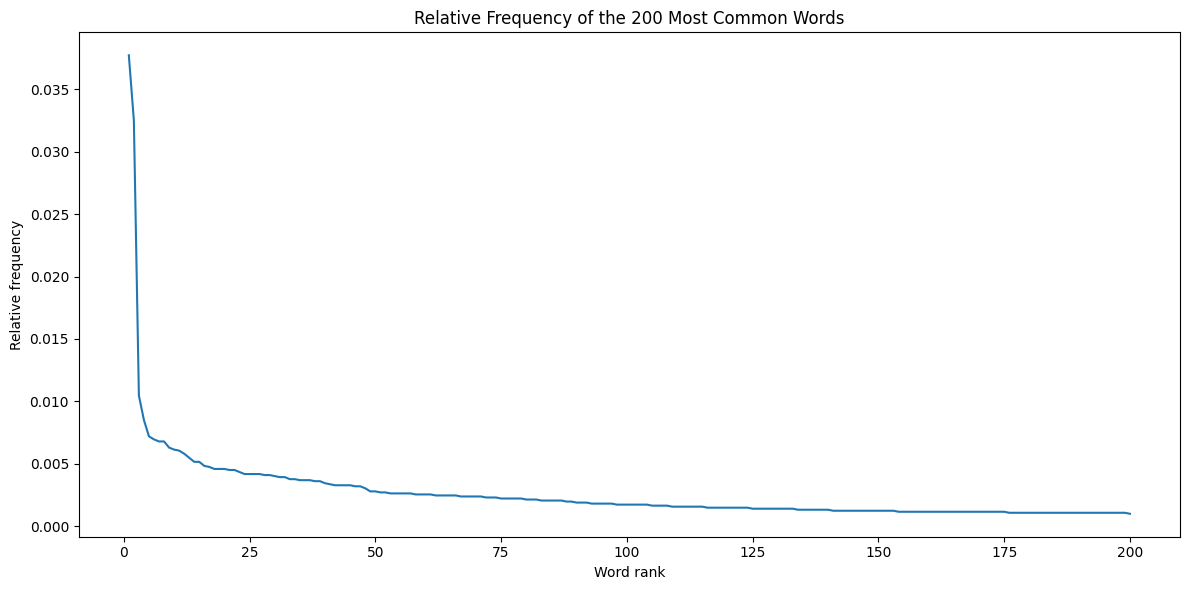

In [ ]:
#Plot the top 200 words
plt.figure(figsize=(12, 6))

plt.plot(results["rank"], results["relative_frequency"])

plt.xlabel("Word rank")
plt.ylabel("Relative frequency")
plt.title("Relative Frequency of the Top 200 Words")

plt.tight_layout()
plt.show()

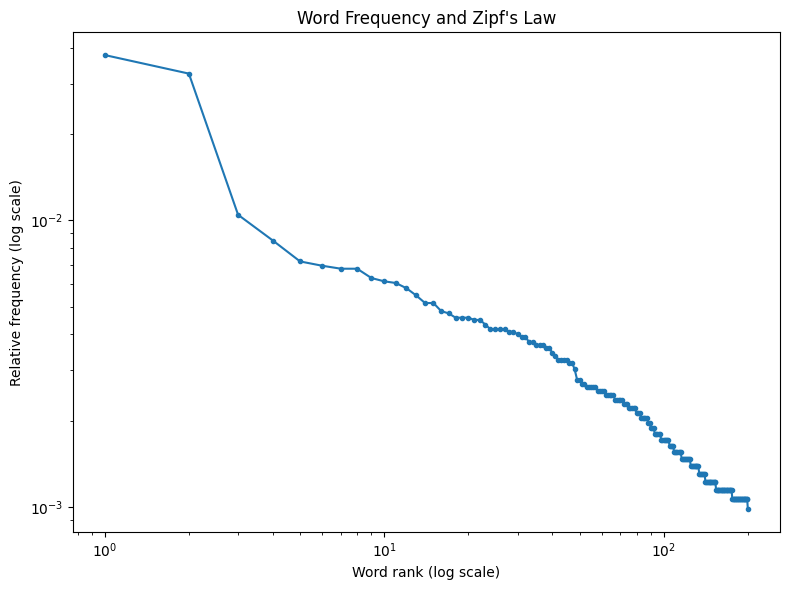

In [30]:

plt.figure(figsize=(8, 6))

plt.loglog(results["rank"], results["relative_frequency"], marker=".")

plt.xlabel("Word rank (log scale)")
plt.ylabel("Relative frequency (log scale)")
plt.title("Word Frequency and Zipf's Law")

plt.tight_layout()
plt.show()


Zipf's law predicts that word frequency decreases approximately in inverse proportion to word rank. A log-log graph that is downward sloping shows an approximate Zipf-like pattern. In this chart, the points are relatively sparse toward the top, where the highest-ranked words have much greater frequencies. As the rank increases, the points become more concentrated and follow a downward pattern that slopes down. This illustrates the inverse relationship between a word's rank and its frequency, although the distribution is not perfectly linear.


## Conclusion

Overall, the analysis showed that word frequency is not evenly distributed throughout the corpus. A relatively small number of unique words account for a large portion of total word occurrences. After removing common stop words, 174 unique words accounted for approximately 50.06% of all word occurrences, demonstrating how frequently certain words appear compared with the rest of the vocabulary.

The top 200 most frequent words also show this uneven distribution pattern. The Zipf's Law chart showed a downward trend, with relatively sparse points among the highest-ranked words that became more concentrated as word rank increased. This pattern generally supports Zipf's Law, which describes the inverse relationship between a word's rank and its frequency.

The frequency distribution also reflects the fact that this corpus comes from a single book rather than a collection of all types of writing. The book's characters, writing style, settings, and themes influence which words appear most frequently. For example, character names and story-specific vocabulary may occur more often than they would in a broader collection of texts, like alice and queen. Removing stop words also makes the distribution of content-specific words more apparent.

Overall, this analysis helps demonstrate how word frequency can reveal patterns in language and how the characteristics of a particular text influence its vocabulary and word distribution.